# **AI computational essay**
Guilherme Schnekenberg Teixeira - RA00336189

# como uma máquina aprende?

um ensaio computacional curto sobre inteligência artificial, em python.

na programação tradicional, uma pessoa escreve a regra e o computador a executa. na inteligência artificial, a pessoa entrega exemplos e o computador descobre a regra sozinho. neste ensaio vemos isso acontecer em poucas linhas de código: primeiro uma máquina descobre a fórmula de um termômetro a partir de medições com erro; depois ela ajusta seus números passo a passo até errar o mínimo possível; por fim, um modelo minúsculo aprende a prever a próxima palavra de um texto, que é a mesma tarefa usada para treinar os assistentes de conversa atuais.

importamos numpy para os cálculos e matplotlib para os gráficos, e fixamos a semente aleatória para que os resultados se repitam:

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from collections import Counter, defaultdict
rng = np.random.default_rng(42)

ajustamos a aparência dos gráficos (esta célula pode ser ignorada):

In [ ]:
azul, laranja = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.figsize": (6, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
                     "axes.axisbelow": True, "legend.frameon": False})

## 1. aprender com exemplos

a conversão de celsius para fahrenheit tem uma regra conhecida: f = 1,8 · c + 32. vamos fingir que não a conhecemos. temos apenas um termômetro barato, que erra alguns graus para cima ou para baixo, e queremos que a máquina descubra a regra olhando para as medições.

geramos 30 medições com ruído (a máquina nunca verá os números 1,8 e 32):

In [ ]:
c = rng.uniform(-10, 40, 30)
f = 1.8 * c + 32 + rng.normal(0, 3, 30)

as cinco primeiras medições, em pares (°c, °f):

In [ ]:
np.column_stack([c, f])[:5].round(1)

array([[28.7, 90.1],
       [11.9, 52.3],
       [32.9, 89.7],
       [24.9, 74.3],
       [-5.3, 24.3]])

todas as medições num gráfico:

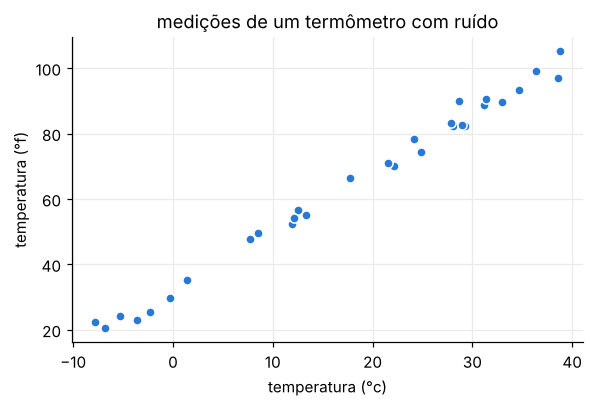

In [ ]:
plt.scatter(c, f, color=azul, edgecolor="white")
plt.xlabel("temperatura (°c)"); plt.ylabel("temperatura (°f)"); plt.title("medições de um termômetro com ruído")
plt.show()

os pontos seguem uma reta, mas com dispersão. a máquina vai procurar a reta f = w · c + b que melhor passa por eles. w e b são dois números ajustáveis, como dois botões. para saber se os botões estão bem ajustados, medimos o erro quadrático médio: a média dos quadrados das diferenças entre o que o modelo prevê e o que foi medido.

o modelo e a sua medida de erro:

In [ ]:
def modelo(c, w, b): return w * c + b
def erro(w, b): return float(np.mean((modelo(c, w, b) - f) ** 2))

com os dois botões em zero, a máquina ainda não sabe nada e o erro é enorme:

In [ ]:
erro(0, 0)

4865.878414235572

## 2. descer a ladeira do erro

o erro depende de w e de b, como a altura de um terreno depende da posição. aprender é descer até o ponto mais baixo desse terreno. a derivada do erro indica para que lado o terreno desce, e então damos um pequeno passo nessa direção. esse método se chama descida de gradiente, e é o mesmo usado para treinar os grandes modelos de ia, só que com bilhões de botões em vez de dois.

um passo de aprendizado, que move w e b ladeira abaixo:

In [ ]:
def passo(w, b, taxa=1e-3):
    r = modelo(c, w, b) - f
    return w - taxa * 2 * np.mean(r * c), b - taxa * 2 * np.mean(r)

repetimos o passo 20 000 vezes, guardando o erro a cada passo:

In [ ]:
w, b, historico = 0.0, 0.0, []
for _ in range(20_000): w, b = passo(w, b); historico.append(erro(w, b))

o erro cai rapidamente e depois se estabiliza:

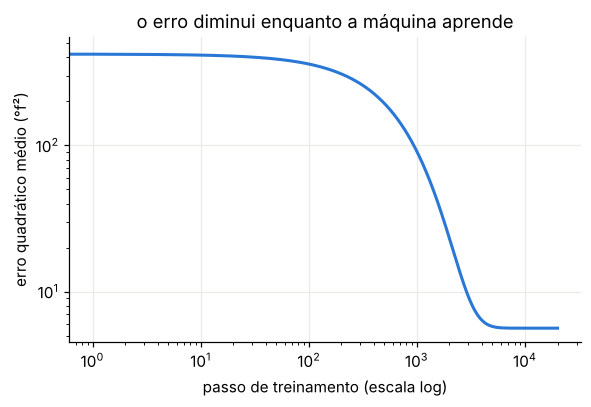

In [ ]:
plt.plot(historico, color=azul, lw=2); plt.xscale("log"); plt.yscale("log")
plt.xlabel("passo de treinamento (escala log)"); plt.ylabel("erro quadrático médio (°f²)"); plt.title("o erro diminui enquanto a máquina aprende")
plt.show()

os valores aprendidos, para comparar com a regra verdadeira (1,8 e 32):

In [ ]:
round(float(w), 2), round(float(b), 1)

(1.79, 32.5)

a reta aprendida desenhada sobre as medições:

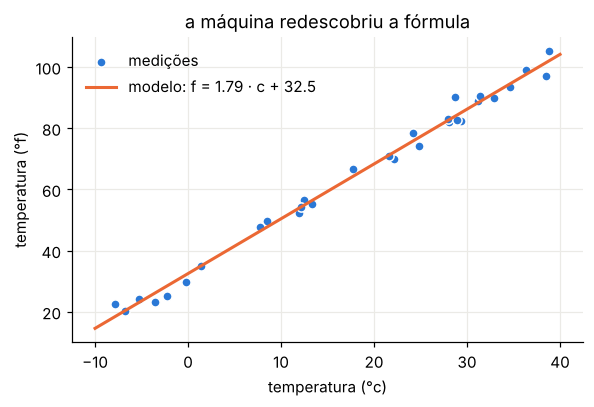

In [ ]:
plt.scatter(c, f, color=azul, edgecolor="white", label="medições")
plt.plot([-10, 40], [modelo(-10, w, b), modelo(40, w, b)], color=laranja, lw=2, label=f"modelo: f = {w:.2f} · c + {b:.1f}")
plt.xlabel("temperatura (°c)"); plt.ylabel("temperatura (°f)"); plt.title("a máquina redescobriu a fórmula"); plt.legend(); plt.show()

ninguém escreveu a regra 1,8 · c + 32: ela surgiu dos dados. a pequena diferença em relação aos valores exatos vem do ruído do termômetro. aprender, para uma máquina, é isto: ajustar números para diminuir um erro.

## 3. prever a próxima palavra

os modelos de linguagem que conversam conosco são treinados numa tarefa simples: dado um trecho de texto, prever a próxima palavra. a versão mais simples possível olha apenas para a última palavra e pergunta: no texto de treino, o que costuma vir depois dela?

um pequeno texto de treino, em que o ponto final conta como uma palavra:

In [ ]:
texto = """a máquina aprende com exemplos . a máquina aprende com dados . o modelo aprende com dados e erros .
o modelo prevê a próxima palavra . a rede prevê a próxima palavra . a máquina encontra padrões nos dados .
o modelo encontra padrões nas palavras . a próxima palavra depende das palavras anteriores .
o erro ajuda a máquina a aprender . aprender é ajustar números . prever é escolher a palavra mais provável ."""
palavras = texto.split()

contamos quantas vezes cada palavra aparece logo depois de cada outra:

In [ ]:
seguintes = defaultdict(Counter)
for atual, proxima in zip(palavras, palavras[1:]): seguintes[atual][proxima] += 1

transformamos as contagens em probabilidades. por exemplo, o que vem depois de "a":

In [ ]:
def probabilidades(p): total = sum(seguintes[p].values()); return {k: v / total for k, v in seguintes[p].most_common()}
probabilidades("a")

{'máquina': 0.4, 'próxima': 0.3, 'rede': 0.1, 'aprender': 0.1, 'palavra': 0.1}

as mesmas probabilidades num gráfico de barras:

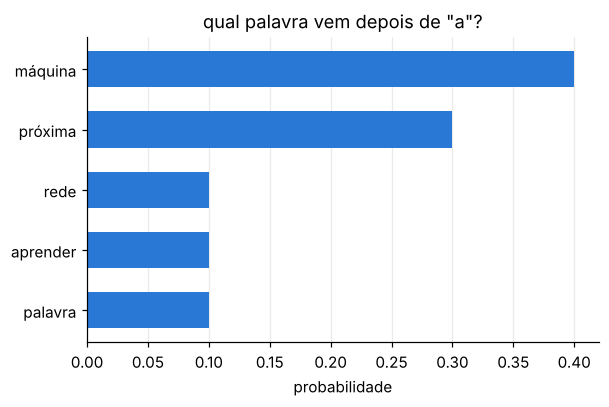

In [ ]:
d = probabilidades("a"); plt.barh(list(d)[::-1], list(d.values())[::-1], color=azul, height=0.6)
plt.xlabel("probabilidade"); plt.title("qual palavra vem depois de \"a\"?"); plt.grid(axis="y", visible=False); plt.show()

para escrever, o modelo sorteia a próxima palavra de acordo com essas probabilidades, acrescenta essa palavra ao texto e repete até chegar a um ponto final.

a função que gera uma frase:

In [ ]:
def gerar(inicio):
    frase = inicio.split()
    while frase[-1] != "." and len(frase) < 15:
        opcoes = seguintes[frase[-1]]; frase.append(rng.choice(list(opcoes), p=np.array(list(opcoes.values())) / sum(opcoes.values())))
    return " ".join(frase)

cinco frases geradas a partir de "o modelo":

In [ ]:
for _ in range(5): print(gerar("o modelo"))

o modelo prevê a próxima palavra depende das palavras .
o modelo aprende com dados .
o modelo aprende com exemplos .
o modelo prevê a próxima palavra mais provável .
o modelo aprende com dados .


algumas frases geradas não existem no texto de treino: o modelo recombina pedaços e cria algo novo. como ele só enxerga uma palavra para trás, porém, frases longas tendem a perder o sentido.

### fechamento

as duas ideias deste ensaio são a base da inteligência artificial atual. a primeira: aprender é ajustar números para diminuir um erro. a segunda: um modelo de linguagem é uma máquina de prever a próxima palavra. os grandes modelos juntam as duas, usando a descida de gradiente da seção 2 para ajustar bilhões de números e enxergando milhares de palavras para trás, e não apenas uma.

para experimentar: troque o texto da seção 3 por um texto seu, ou aumente o ruído do termômetro na seção 1 e veja como os valores aprendidos se afastam de 1,8 e 32.